# Trying pySRIM on myself

## configuration

In [ ]:
#%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
from collections import Counter
from itertools import count
from random import randint
from pathlib import Path
import math

# Only needed to embed the images in notebook so they
# show up in gitlab repo
from IPython.display import Image

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import gaussian_kde
import seaborn

from srim import TRIM, Target, Layer, Ion, Element

In [14]:
# Construct a 3MeV Nickel ion
ion = Ion('Ni', energy=3.0e6)
print(ion)

<Ion element:Nickel mass:58.69 energy:3.00E+06 eV>


In [15]:
# Construct a layer of nick 20um thick with a displacement energy of 30 eV
layer = Layer({
        'Ni': {
            'stoich': 1.0,
            'E_d': 30.0,
            'lattice': 0.0,
            'surface': 3.0
        }}, density=8.9, width=20000.0)
print(layer)

<Layer material:Ni 1.00 width:20000.0>


In [16]:
# Construct a target of a single layer of Nickel
target = Target([layer])
#print(target)

In [18]:
# Initialize a TRIM calculation with given target and ion for 25 ions, quick calculation
trim = TRIM(target,
            ion,
            number_ions=25,
            calculation=1)
#print(trim)

In [19]:
# Specify the directory of SRIM.exe
# For windows users the path will include C://...
srim_executable_directory = r'C:\Program Files\SRIM-2013'

In [20]:
# takes about 10 seconds on my laptop
results = trim.run(srim_executable_directory)
# If all went successfull you should have seen a TRIM window popup and run 25 ions!
# results is `srim.output.Results` and contains all output files parsed

In [21]:
output_directory = r'C:\Users\Sacha\Desktop\nazar\examples\otherone'
os.makedirs(output_directory, exist_ok=True)
TRIM.copy_output_files(srim_executable_directory, output_directory)

In [22]:
results = Results(srim_executable_directory)

In [25]:
def plot_damage_energy(folder, ax):
    results = Results(folder)
    phon = results.phonons
    dx = max(phon.depth) / 100.0 # to units of Angstroms
    energy_damage = (phon.ions + phon.recoils) * dx
    ax.plot(phon.depth, energy_damage / phon.num_ions, label='{}'.format(folder))
    return sum(energy_damage)

def plot_ionization(folder, ax):
    results = Results(folder)
    ioniz = results.ioniz
    dx = max(ioniz.depth) / 100.0 # to units of Angstroms
    ax.plot(ioniz.depth, ioniz.ions, label='Ionization from Ions')
    ax.plot(ioniz.depth, ioniz.recoils, label='Ionization from Recoils')

def plot_vacancies(folder, ax):
    results = Results(folder)
    vac = results.vacancy
    vacancy_depth = vac.knock_ons + np.sum(vac.vacancies, axis=1)
    ax.plot(vac.depth, vacancy_depth, label="Total vacancies at depth")
    return sum(vacancy_depth)

folders = [r'C:\Users\Sacha\Desktop\nazar\examples\otherone']#, r'C:\Users\Sacha\Desktop\nazar\examples']
image_directory = r'C:\Users\Sacha\Desktop\nazar\examples'
os.makedirs(image_directory, exist_ok=True)

## original tuto plots

Damage energy: nan eV


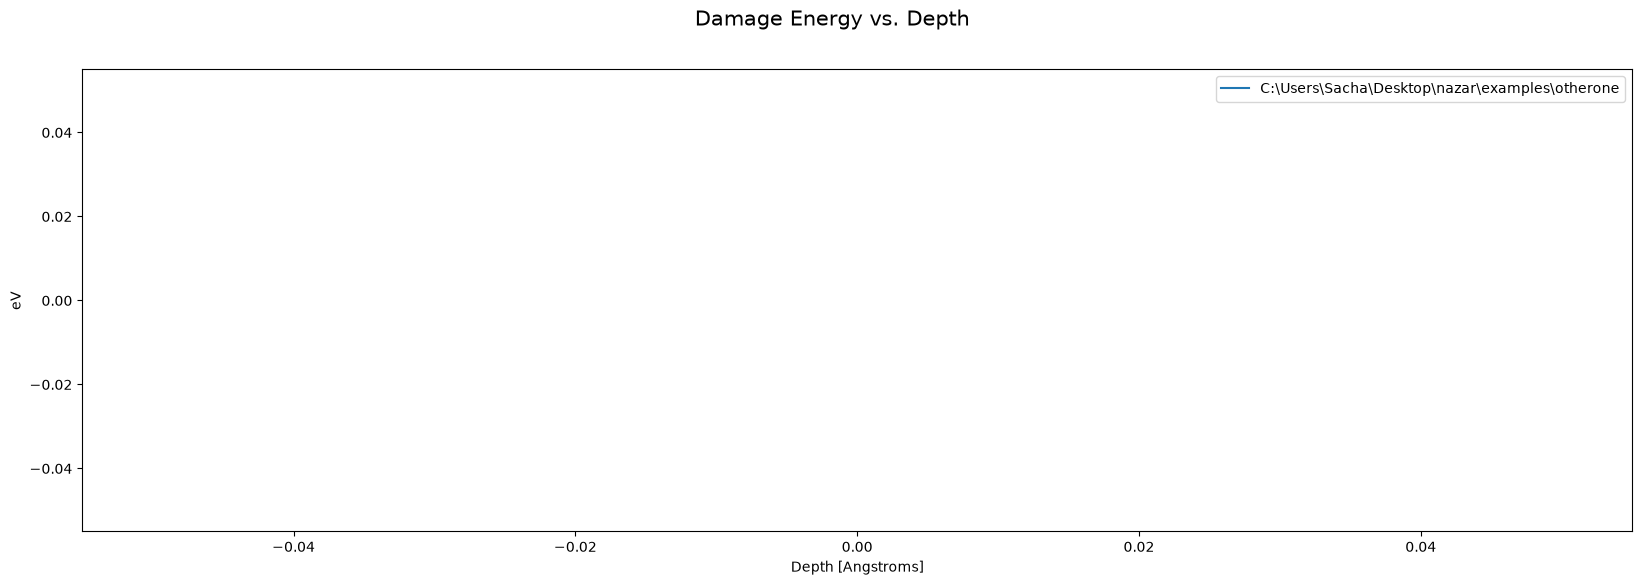

In [26]:
fig, axes = plt.subplots(1, len(folders), sharex=True, sharey=True)

for ax, folder in zip(np.ravel(axes), folders):
    energy_damage = plot_damage_energy(folder, ax)
    print("Damage energy: {} eV".format(energy_damage))
    ax.set_xlabel('Depth [Angstroms]')
    ax.set_ylabel('eV')
    ax.legend()

fig.suptitle('Damage Energy vs. Depth', fontsize=15)
fig.set_size_inches((20, 6))
fig.savefig(os.path.join(image_directory, 'damagevsdepth.png'), transparent=True)

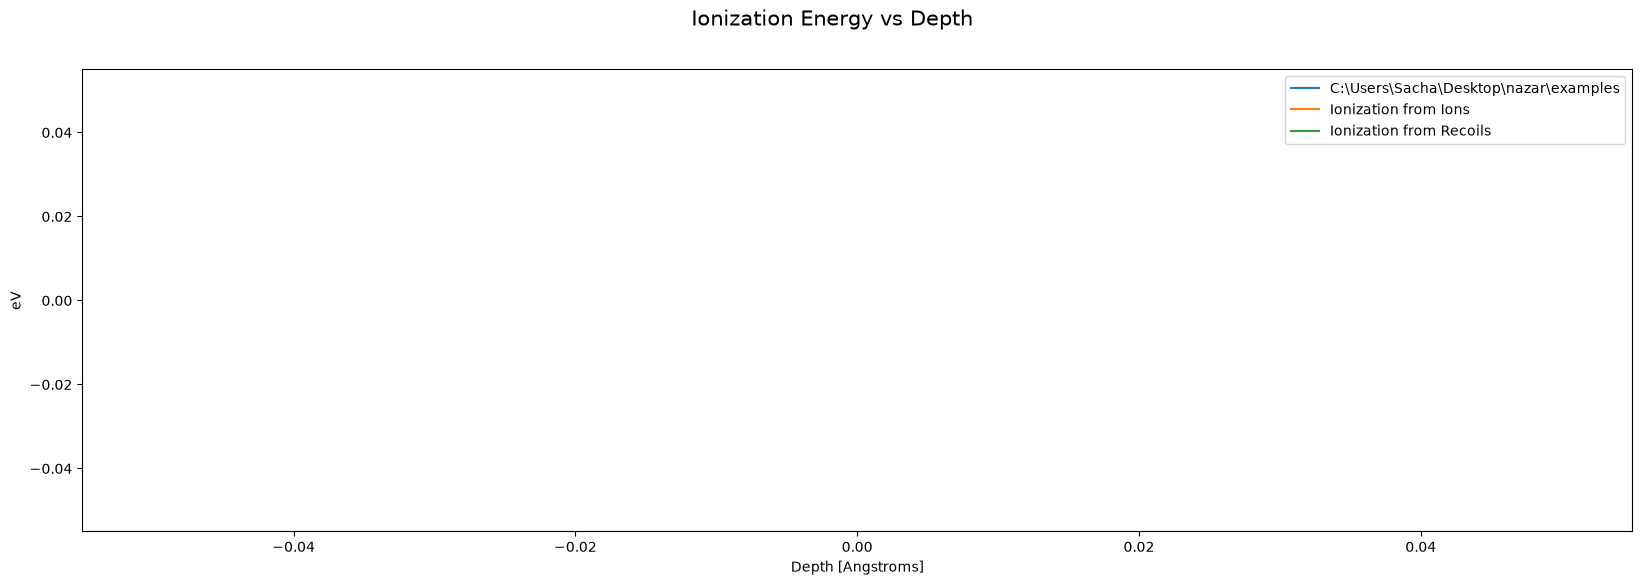

In [12]:
fig, axes = plt.subplots(1, len(folders), sharey=True, sharex=True)

for ax, folder in zip(np.ravel(axes), folders):
    plot_damage_energy(folder, ax)
    plot_ionization(folder, ax)
    ax.legend()
    ax.set_ylabel('eV')
    ax.set_xlabel('Depth [Angstroms]')
fig.suptitle('Ionization Energy vs Depth', fontsize=15)
fig.set_size_inches((20, 6))
fig.savefig(os.path.join(image_directory, 'ionizationvsdepth.png'), transparent=True)

Total number of vacancies C:\Users\Sacha\Desktop\nazar\examples: nan


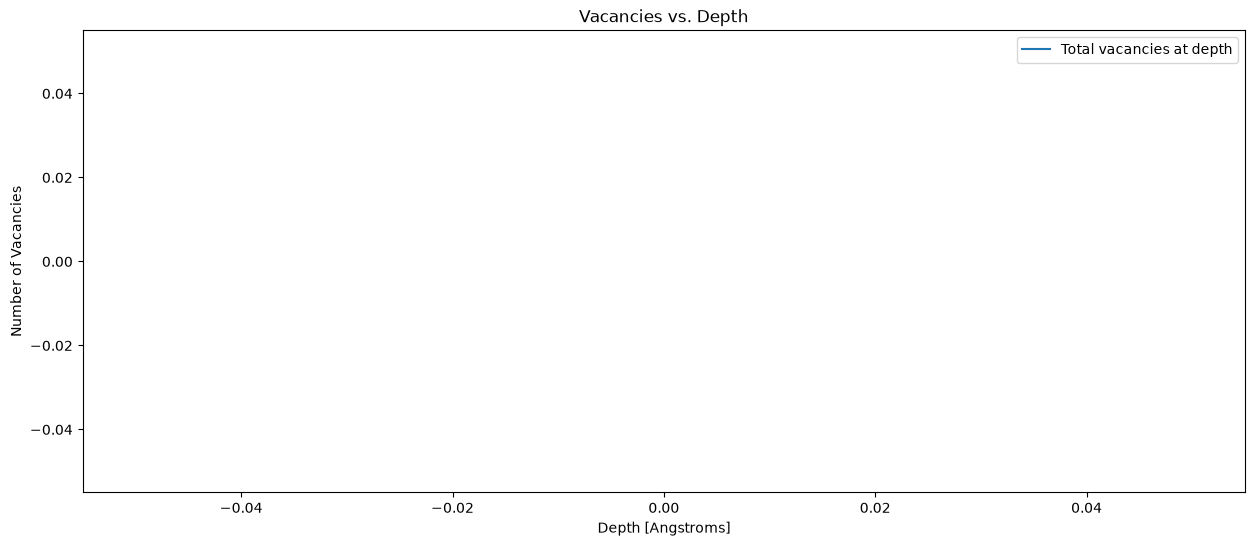

In [13]:
fig, ax = plt.subplots()

for i, folder in enumerate(folders):
    total_vacancies = plot_vacancies(folder, ax)
    print("Total number of vacancies {}: {}".format(folder, total_vacancies))

ax.set_xlabel('Depth [Angstroms]')
ax.set_ylabel('Number of Vacancies')
ax.set_title('Vacancies vs. Depth')
ax.legend()
fig.set_size_inches((15, 6))
fig.savefig(os.path.join(image_directory, 'vacanciesvsdepth.png'), transparent=True)

## my plots

In [31]:
def read_data_from_ioniz_file(file_path):

    path_to_SRIM = r'C:\Users\Sacha\Desktop\nazar\examples'
    folder_to_sel = file_path
    file_to_read = 'IONIZ.txt'
    tot_path = os.path.join(path_to_SRIM, folder_to_sel, file_to_read)

    with open(tot_path, 'r') as f:
        lines = f.readlines()
    separator_index = None
    for i, line in enumerate(lines):
        if line.strip().startswith('-----------  -'):
            separator_index = i
            break
    if separator_index is not None:
        list_line_range = [line.strip() for line in lines[separator_index + 1:] if line.strip()]
        target_depth = [] #Angstrom
        ioniz_by_ion = [] #eV/Angstrom
        ioniz_by_recoils = [] #eV/Angstrom
        for line in list_line_range:
            target_depth.append(float(line.split('  ')[0].replace(',','.')))
            ioniz_by_ion.append(float(line.split('  ')[1].replace(',','.')))
            ioniz_by_recoils.append(float(line.split('  ')[2].replace(',','.')))
        range_data = pd.DataFrame({'target depth (Angstrom)': target_depth, 'ionization by ion (eV/Angstrom)': ioniz_by_ion, 'ionization by recoils (eV/Angstrom)': ioniz_by_recoils})
        return range_data
    else:
        print("Separator line not found in the file.")
        return None

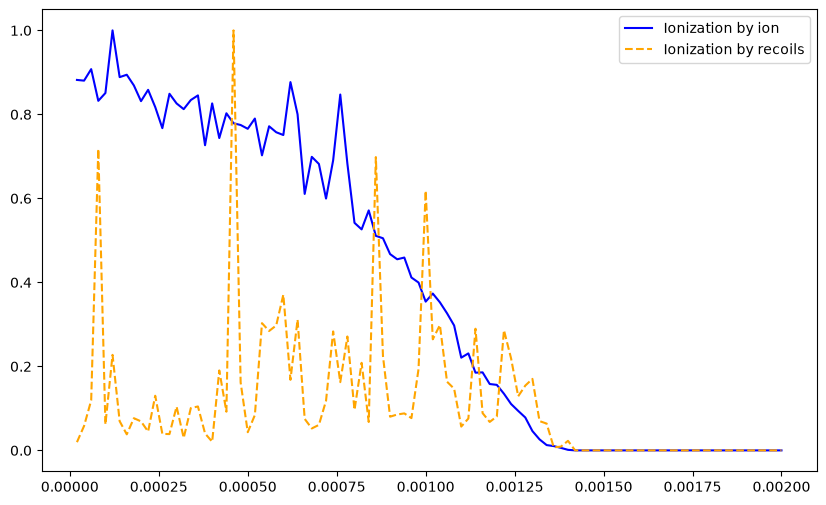

In [32]:
IoFirst = read_data_from_ioniz_file('otherone/')
ion_norm = IoFirst['ionization by ion (eV/Angstrom)'][:]/IoFirst['ionization by ion (eV/Angstrom)'].max()
recoil_norm = IoFirst['ionization by recoils (eV/Angstrom)'][:]/IoFirst['ionization by recoils (eV/Angstrom)'].max()
plt.figure(figsize=(10, 6))
plt.plot(IoFirst['target depth (Angstrom)']*1e-7, ion_norm, label='Ionization by ion', color='blue')
plt.plot(IoFirst['target depth (Angstrom)']*1e-7, recoil_norm, label='Ionization by recoils', color='orange', linestyle='--')
plt.legend()
plt.show()